<a href="https://colab.research.google.com/github/vibhar5/4IK25CS237_DAV_LAB/blob/main/4IK25CS237_EXP_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import  train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import r2_score,mean_squared_error



In [ ]:
df = pd.read_csv('/content/Titanic-Dataset.csv')
df = df[['Fare', 'Pclass', 'Age', 'SibSp', 'Parch']]
df['Age']= df['Age'].fillna(df['Age'].median())
df=df[df['Fare']>0]

In [ ]:
from sklearn.linear_model import LinearRegression

X_simple = df[['Pclass']]
y = df['Fare']

# Fixed random_state to be an integer (42 instead of 4.2)
X_tr, X_te, y_tr, y_te = train_test_split(X_simple, y, test_size=0.2, random_state=42)

# Switched LogisticRegression to LinearRegression since 'Fare' is continuous
model_simple = LinearRegression().fit(X_tr, y_tr)
pred_simple = model_simple.predict(X_te)

print("SIMPLE REGRESSION -- Intercept:", round(model_simple.intercept_, 2))
print("SIMPLE REGRESSION -- Slope:", round(model_simple.coef_[0], 2))
print("SIMPLE REGRESSION -- R2:", round(r2_score(y_te, pred_simple), 2))
print("SIMPLE REGRESSION -- RMSE:", round(mean_squared_error(y_te, pred_simple), 2))

SIMPLE REGRESSION -- Intercept: 112.38
SIMPLE REGRESSION -- Slope: -34.23
SIMPLE REGRESSION -- R2: 0.37
SIMPLE REGRESSION -- RMSE: 1272.78


In [ ]:
X_multi = df[['Pclass', 'Age', 'SibSp', 'Parch']]
X_tr, X_te2, y_tr2, y_te2 = train_test_split(X_multi, y, test_size=0.2, random_state=42)
model_multi = LinearRegression().fit(X_tr, y_tr)
pred_multi = model_multi.predict(X_te2)
print('\nMultiple regression -- interecept', round(model_multi.intercept_, 2))
for name, coef in zip(X_multi.columns, model_multi.coef_):
  print('Multiple regressionx--coefficient of', name, ':', round(coef, 2))
print('Multiple regression -- R2', round(r2_score(y_te2, pred_multi), 3))
print('Multiple regression -- RMSE', round(np.sqrt(mean_squared_error(y_te2, pred_multi)), 2))


Multiple regression -- interecept 112.3
Multiple regressionx--coefficient of Pclass : -35.72
Multiple regressionx--coefficient of Age : -0.12
Multiple regressionx--coefficient of SibSp : 5.38
Multiple regressionx--coefficient of Parch : 10.09
Multiple regression -- R2 0.462
Multiple regression -- RMSE 33.0


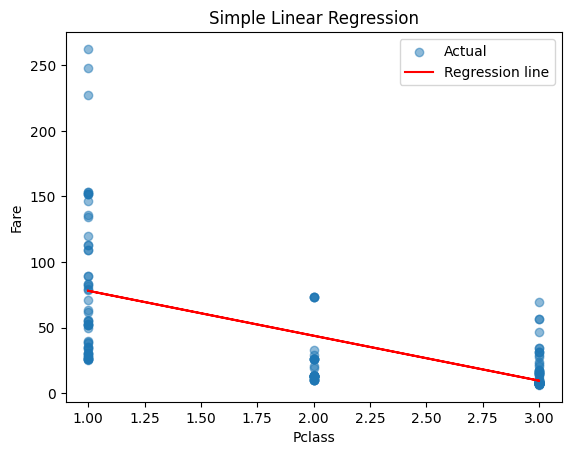

In [ ]:
plt.scatter(X_te['Pclass'], y_te, alpha=0.5, label='Actual')
plt.plot(X_te['Pclass'], pred_simple, color='red', label='Regression line')
plt.xlabel('Pclass')
plt.ylabel('Fare')
plt.title('Simple Linear Regression')
plt.legend()
plt.show()

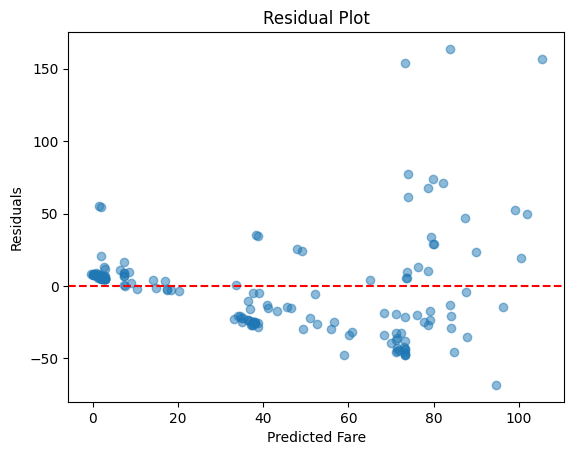

In [ ]:
residuals=y_te2-pred_multi
plt.scatter(pred_multi, residuals,alpha=0.5)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Predicted Fare');plt.ylabel('Residuals');plt.title('Residual Plot')
plt.show()


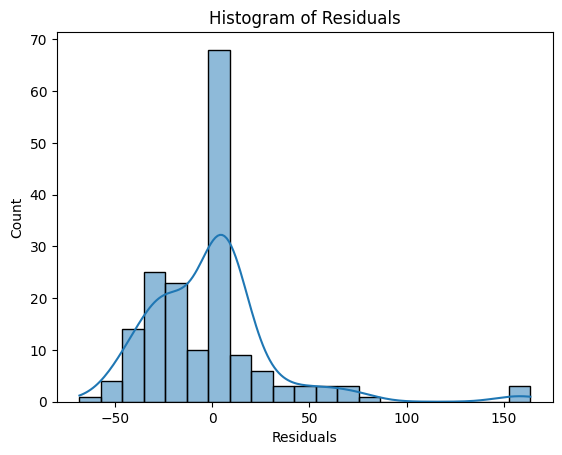

In [ ]:
sns.histplot(residuals,kde=True)
plt.xlabel('Residuals');plt.title('Histogram of Residuals')
plt.show()

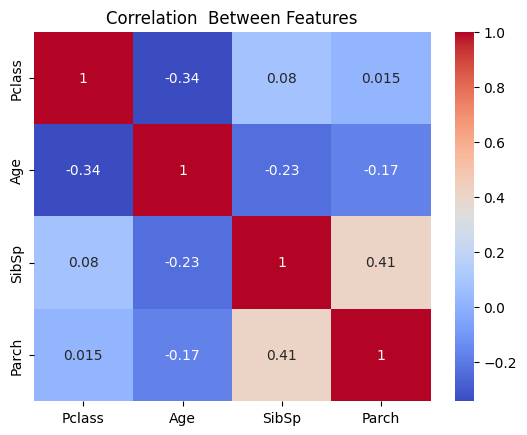

In [ ]:
sns.heatmap(X_multi.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation  Between Features')
plt.show()